# Stream C — `evidence_retrieval.ipynb`

**Purpose:** Build an evidence retrieval system for each image-caption pair using
CLIP-based nearest-neighbour search over the training corpus embeddings.

**Why not Google Vision API / web search:**
- Requires paid API key + rate limits make 85K+ pairs infeasible
- All pre-extracted embeddings are already on disk — we can do fully offline retrieval
- CLIP-NN retrieval is used in published EVE-style systems (Abdelnabi et al., 2022)

**Stream C strategy:**
For each test/val pair (image_id, caption):
1. Retrieve top-K most similar images from the **training corpus** using CLIP image embeddings (FAISS)
2. For each retrieved neighbour, collect its caption from NC metadata
3. Compute **image-to-image similarity** (visual evidence strength)
4. Compute **retrieved-caption-to-query-caption similarity** (textual stance score)
5. Aggregate into evidence features: `[max_sim, mean_sim, std_sim, top1_txt_sim, stance_score]`

**Output:** `cache/evidence/evidence_{split}.pkl` — one feature vector per pair

**Expected runtime:** ~5 min (FAISS index build) + ~2 min (retrieval)

## 0. Environment Check

In [13]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"PyTorch: {torch.__version__}")

# Check faiss
try:
    import faiss
    print(f"faiss version: {faiss.__version__}")
except ImportError:
    print("faiss not found — installing ...")
    import subprocess
    subprocess.run(['pip', 'install', 'faiss-cpu', '-q'], check=True)
    import faiss
    print(f"faiss installed: {faiss.__version__}")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB
PyTorch: 2.6.0+cu124
faiss version: 1.13.2


## 1. Imports & Paths

In [14]:
import os, sys, json, pickle
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')
import faiss

# ── Project root ──────────────────────────────────────────────────────────────
try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

CLIP_EMB_DIR  = ROOT / 'cache' / 'clip_embeddings'
EVIDENCE_DIR  = ROOT / 'cache' / 'evidence'
STANCE_DIR    = ROOT / 'cache' / 'stance_scores'
NC_META_DIR   = ROOT / 'data' / 'newsclippings' / 'metadata'
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
STANCE_DIR.mkdir(parents=True, exist_ok=True)

# Verify embedding files
for split in ('train', 'val', 'test'):
    img_p = CLIP_EMB_DIR / 'clip_image_embeddings' / f'{split}.pkl'
    txt_p = CLIP_EMB_DIR / 'clip_text_embeddings'  / f'{split}.pkl'
    print(f"  {'✅' if img_p.exists() else '❌'} clip_img {split} | "
          f"{'✅' if txt_p.exists() else '❌'} clip_txt {split}")

for split in ('train', 'val', 'test'):
    meta_p = NC_META_DIR / f'{split}.json'
    print(f"  {'✅' if meta_p.exists() else '❌'} metadata/{split}.json")

Project root: f:\GitHub\eve-rag
  ✅ clip_img train | ✅ clip_txt train
  ✅ clip_img val | ✅ clip_txt val
  ✅ clip_img test | ✅ clip_txt test
  ✅ metadata/train.json
  ✅ metadata/val.json
  ✅ metadata/test.json


## 2. Load Embeddings & Metadata

In [15]:
def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

print("Loading CLIP embeddings …")
clip_img = {s: load_pkl(CLIP_EMB_DIR / 'clip_image_embeddings' / f'{s}.pkl')
            for s in ('train', 'val', 'test')}
clip_txt = {s: load_pkl(CLIP_EMB_DIR / 'clip_text_embeddings'  / f'{s}.pkl')
            for s in ('train', 'val', 'test')}

for s in ('train', 'val', 'test'):
    print(f"  {s}: img={len(clip_img[s])}  txt={len(clip_txt[s])}")

# Load NC JSON splits (root-level)
print("\nLoading NC split JSONs …")
nc_json = {}
for split, path in [
    ('train', ROOT / 'data' / 'newsclippings' / 'train.json'),
    ('val',   ROOT / 'data' / 'newsclippings' / 'data' / 'merged_balanced' / 'val.json'),
    ('test',  ROOT / 'data' / 'newsclippings' / 'test.json'),
]:
    with open(path) as f:
        data = json.load(f)
    nc_json[split] = data if isinstance(data, list) else data.get('annotations', [])
    print(f"  {split}: {len(nc_json[split])} pairs")

# Load metadata for captions
print("\nLoading NC metadata (captions) …")
meta = {}
for split in ('train', 'val', 'test'):
    with open(NC_META_DIR / f'{split}.json') as f:
        raw = json.load(f)
    # metadata keyed by id (int or str) → normalise to int
    if isinstance(raw, list):
        meta[split] = {int(r['id']): r for r in raw}
    elif isinstance(raw, dict):
        meta[split] = {int(k): v for k, v in raw.items()}
    print(f"  {split}: {len(meta[split])} entries")

Loading CLIP embeddings …
  train: img=473663  txt=385850
  val: img=50000  txt=40864
  test: img=50000  txt=40915

Loading NC split JSONs …
  train: 71072 pairs
  val: 7024 pairs
  test: 7264 pairs

Loading NC metadata (captions) …
  train: 385003 entries
  val: 40830 entries
  test: 40915 entries


## 3. Build FAISS Index on Training Image Embeddings

We index the **training set** images so that for any query image (val/test),
we can retrieve the most visually similar training images and their captions.

In [16]:
# Build flat (image_id → position) mapping for training set
train_img_ids   = sorted(clip_img['train'].keys())   # list of int image_ids
train_img_id_to_pos = {iid: pos for pos, iid in enumerate(train_img_ids)}

# Stack train image embeddings into (N, 512) matrix
def to_float32(v):
    arr = np.array(v, dtype=np.float32)
    if arr.ndim > 1: arr = arr.flatten()[:512]
    return arr

print("Building FAISS index on training image embeddings …")
train_img_matrix = np.vstack([
    to_float32(clip_img['train'][iid]) for iid in train_img_ids
]).astype(np.float32)  # (N_train_imgs, 512)

# L2-normalise for cosine similarity via inner product
faiss.normalize_L2(train_img_matrix)

DIM = train_img_matrix.shape[1]
print(f"  Matrix shape: {train_img_matrix.shape}  dim={DIM}")

# IndexFlatIP = exact inner product (= cosine after L2 norm)
index = faiss.IndexFlatIP(DIM)
index.add(train_img_matrix)
print(f"  FAISS index built: {index.ntotal} vectors")

# Also build a text embedding lookup for training captions
# (pair_id → caption text, from metadata)
train_pair_ids  = [int(r['id']) for r in nc_json['train']]
train_falsified = [int(r['falsified']) for r in nc_json['train']]
train_image_ids_per_pair = [int(r['image_id']) for r in nc_json['train']]

# Map image_id → list of (pair_id, caption) in training set
from collections import defaultdict
train_imgid_to_pairs = defaultdict(list)
for r in nc_json['train']:
    pid = int(r['id'])
    iid = int(r['image_id'])
    cap = ''
    if pid in meta['train']:
        cap = str(meta['train'][pid].get('caption', ''))
    train_imgid_to_pairs[iid].append({'pair_id': pid, 'caption': cap,
                                       'falsified': int(r['falsified'])})

print(f"  Training pairs indexed: {sum(len(v) for v in train_imgid_to_pairs.values())}")

Building FAISS index on training image embeddings …
  Matrix shape: (473663, 512)  dim=512
  FAISS index built: 473663 vectors
  Training pairs indexed: 71072


## 4. Evidence Retrieval Function

For each query (image_id, pair_id, caption), retrieve top-K training images
and compute:
- `img_sim_*` — image-to-image similarity statistics (max, mean, std, top1)
- `txt_sim_*` — query caption vs retrieved captions (CLIP text cosine)
- `stance_score` — cross-modal: query image vs retrieved captions

In [17]:
K = 10   # top-K neighbours to retrieve

def cosine(a, b):
    a = a / (np.linalg.norm(a) + 1e-8)
    b = b / (np.linalg.norm(b) + 1e-8)
    return float(np.dot(a, b))


def retrieve_evidence(query_img_id, query_pair_id, query_split,
                       k=K):
    """
    Returns a feature dict for one pair.

    Features:
      img_sim_max, img_sim_mean, img_sim_std, img_sim_top1  — visual similarity
      txt_sim_max, txt_sim_mean, txt_sim_top1               — caption similarity
      cross_sim_max, cross_sim_mean                         — query img vs retrieved caps
      stance_score                                          — weighted txt-img stance
      n_retrieved                                           — actual neighbours found
    """
    # Query embeddings
    q_img_raw = clip_img[query_split].get(int(query_img_id))
    q_txt_raw = clip_txt[query_split].get(int(query_pair_id))

    if q_img_raw is None or q_txt_raw is None:
        return _zero_features()

    q_img = to_float32(q_img_raw)
    q_txt = to_float32(q_txt_raw)

    # FAISS search
    q_norm = q_img / (np.linalg.norm(q_img) + 1e-8)
    q_norm = q_norm.reshape(1, -1).astype(np.float32)
    sims, idxs = index.search(q_norm, k + 1)   # +1 to skip self if present
    sims = sims[0]   # (k+1,)
    idxs = idxs[0]

    # Collect neighbours (skip if same image_id)
    neighbour_img_sims = []
    neighbour_txt_sims = []
    neighbour_cross_sims = []

    for sim, pos in zip(sims, idxs):
        if pos < 0 or pos >= len(train_img_ids): continue
        nb_img_id = train_img_ids[pos]
        if nb_img_id == int(query_img_id): continue   # skip exact self

        neighbour_img_sims.append(float(sim))

        # Caption similarities for this neighbour image
        pairs_for_nb = train_imgid_to_pairs.get(nb_img_id, [])
        for p in pairs_for_nb[:2]:   # max 2 captions per neighbour
            nb_pair_id = p['pair_id']
            nb_cap_raw = clip_txt['train'].get(int(nb_pair_id))
            if nb_cap_raw is None: continue
            nb_txt = to_float32(nb_cap_raw)

            # txt-txt: query caption vs neighbour caption
            neighbour_txt_sims.append(cosine(q_txt, nb_txt))
            # cross: query image vs neighbour caption
            neighbour_cross_sims.append(cosine(q_img, nb_txt))

        if len(neighbour_img_sims) >= k:
            break

    if not neighbour_img_sims:
        return _zero_features()

    img_arr   = np.array(neighbour_img_sims)
    txt_arr   = np.array(neighbour_txt_sims)   if neighbour_txt_sims   else np.zeros(1)
    cross_arr = np.array(neighbour_cross_sims) if neighbour_cross_sims else np.zeros(1)

    # Stance score: how much do retrieved captions support the query image?
    # High cross_sim → retrieved captions semantically match the query image
    # Combined with txt_sim: if retrieved_cap ≈ query_cap AND retrieved_cap ≈ query_img → genuine
    stance = float(np.mean(cross_arr) * np.mean(txt_arr))

    return {
        'img_sim_max':    float(img_arr.max()),
        'img_sim_mean':   float(img_arr.mean()),
        'img_sim_std':    float(img_arr.std()),
        'img_sim_top1':   float(img_arr[0]),
        'txt_sim_max':    float(txt_arr.max()),
        'txt_sim_mean':   float(txt_arr.mean()),
        'txt_sim_top1':   float(txt_arr[0]) if len(txt_arr) > 0 else 0.0,
        'cross_sim_max':  float(cross_arr.max()),
        'cross_sim_mean': float(cross_arr.mean()),
        'stance_score':   stance,
        'n_retrieved':    len(neighbour_img_sims),
    }


def _zero_features():
    return {
        'img_sim_max': 0.0, 'img_sim_mean': 0.0, 'img_sim_std': 0.0,
        'img_sim_top1': 0.0, 'txt_sim_max': 0.0, 'txt_sim_mean': 0.0,
        'txt_sim_top1': 0.0, 'cross_sim_max': 0.0, 'cross_sim_mean': 0.0,
        'stance_score': 0.0, 'n_retrieved': 0,
    }


print(f"Retrieval function ready. K={K}")
print(f"Feature dim per pair: {len(_zero_features())}")

Retrieval function ready. K=10
Feature dim per pair: 11


## 5. Run Retrieval — Val & Test Sets (NC)

In [18]:
def run_retrieval(split):
    pairs   = nc_json[split]
    results = {}
    n_zero  = 0

    for row in tqdm(pairs, desc=f'Retrieving {split}'):
        img_id  = int(row['image_id'])
        pair_id = int(row['id'])
        false   = int(row['falsified'])
        pair_key = f"{pair_id}_{false}"

        feats = retrieve_evidence(img_id, pair_id, split)
        feats['label']    = false
        feats['pair_key'] = pair_key
        feats['image_id'] = img_id
        feats['pair_id']  = pair_id

        if feats['n_retrieved'] == 0:
            n_zero += 1
        results[pair_key] = feats

    print(f"  {split}: {len(results)} pairs | zero-retrieval: {n_zero}")
    return results


evidence = {}
# Run on val and test (train would retrieve from itself — less meaningful)
for split in ('val', 'test'):
    evidence[split] = run_retrieval(split)

# Also run on train (using leave-one-out logic: FAISS will skip exact self)
print("\nRunning on train split (FAISS skips exact-self match) …")
evidence['train'] = run_retrieval('train')

Retrieving val:   0%|          | 0/7024 [00:00<?, ?it/s]

  val: 7024 pairs | zero-retrieval: 0


Retrieving test:   0%|          | 0/7264 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 6. Quick AUROC Check on Evidence Features

In [ ]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

feature_names = [
    'img_sim_max', 'img_sim_mean', 'img_sim_std', 'img_sim_top1',
    'txt_sim_max', 'txt_sim_mean', 'txt_sim_top1',
    'cross_sim_max', 'cross_sim_mean', 'stance_score'
]

for split in ('val', 'test'):
    rows   = list(evidence[split].values())
    labels = np.array([r['label'] for r in rows])
    print(f"\nNC {split} — feature AUROCs (negated where lower=OOC):")
    for feat in feature_names:
        vals = np.array([r[feat] for r in rows], dtype=np.float32)
        if np.std(vals) < 1e-6: continue
        # Try both directions
        auc_pos = roc_auc_score(labels,  vals)
        auc_neg = roc_auc_score(labels, -vals)
        best    = max(auc_pos, auc_neg)
        direction = '↑' if auc_pos > auc_neg else '↓'
        print(f"  {feat:22s}: {best:.4f} {direction}")


NC val — feature AUROCs (negated where lower=OOC):
  img_sim_max           : 0.5034 ↓
  img_sim_mean          : 0.5102 ↓
  img_sim_std           : 0.5088 ↑
  img_sim_top1          : 0.5034 ↓
  txt_sim_max           : 0.5532 ↓
  txt_sim_mean          : 0.5553 ↓
  txt_sim_top1          : 0.5539 ↓
  cross_sim_max         : 0.5006 ↑
  cross_sim_mean        : 0.5019 ↑
  stance_score          : 0.5389 ↓

NC test — feature AUROCs (negated where lower=OOC):
  img_sim_max           : 0.5008 ↓
  img_sim_mean          : 0.5148 ↓
  img_sim_std           : 0.5218 ↑
  img_sim_top1          : 0.5008 ↓
  txt_sim_max           : 0.5513 ↓
  txt_sim_mean          : 0.5532 ↓
  txt_sim_top1          : 0.5465 ↓
  cross_sim_max         : 0.5020 ↑
  cross_sim_mean        : 0.5000 ↑
  stance_score          : 0.5390 ↓


## 7. Also Retrieve for VERITE & MMFakeBench

In [ ]:
# For VERITE and MMFakeBench, we use the pre-extracted CLIP embeddings
# stored in cache/lora_stage2/ (ood_embs_*.pkl)
# Query: OOD image embedding vs NC training corpus

LORA2_DIR = ROOT / 'cache' / 'lora_stage2'

def retrieve_from_raw_embs(emb_dict, desc='OOD'):
    """
    emb_dict: {idx: {clip_img_emb, clip_txt_emb, label}}
    Queries the NC training FAISS index.
    """
    results = {}
    n_zero  = 0

    for idx, entry in tqdm(emb_dict.items(), desc=desc):
        q_img = np.array(entry['clip_img_emb'], dtype=np.float32).flatten()[:512]
        q_txt = np.array(entry['clip_txt_emb'], dtype=np.float32).flatten()[:512]

        q_norm = q_img / (np.linalg.norm(q_img) + 1e-8)
        q_norm = q_norm.reshape(1, -1)
        sims, idxs_faiss = index.search(q_norm, K + 1)
        sims = sims[0]; idxs_faiss = idxs_faiss[0]

        neighbour_img_sims, neighbour_txt_sims, neighbour_cross_sims = [], [], []

        for sim, pos in zip(sims, idxs_faiss):
            if pos < 0 or pos >= len(train_img_ids): continue
            nb_img_id = train_img_ids[pos]
            neighbour_img_sims.append(float(sim))

            for p in train_imgid_to_pairs.get(nb_img_id, [])[:2]:
                nb_txt_raw = clip_txt['train'].get(int(p['pair_id']))
                if nb_txt_raw is None: continue
                nb_txt = to_float32(nb_txt_raw)
                neighbour_txt_sims.append(cosine(q_txt, nb_txt))
                neighbour_cross_sims.append(cosine(q_img, nb_txt))

            if len(neighbour_img_sims) >= K: break

        if not neighbour_img_sims:
            n_zero += 1
            results[idx] = {**_zero_features(), 'label': int(entry['label'])}
            continue

        img_arr   = np.array(neighbour_img_sims)
        txt_arr   = np.array(neighbour_txt_sims)   if neighbour_txt_sims   else np.zeros(1)
        cross_arr = np.array(neighbour_cross_sims) if neighbour_cross_sims else np.zeros(1)
        stance    = float(np.mean(cross_arr) * np.mean(txt_arr))

        results[idx] = {
            'img_sim_max':    float(img_arr.max()),
            'img_sim_mean':   float(img_arr.mean()),
            'img_sim_std':    float(img_arr.std()),
            'img_sim_top1':   float(img_arr[0]),
            'txt_sim_max':    float(txt_arr.max()),
            'txt_sim_mean':   float(txt_arr.mean()),
            'txt_sim_top1':   float(txt_arr[0]) if len(txt_arr) > 0 else 0.0,
            'cross_sim_max':  float(cross_arr.max()),
            'cross_sim_mean': float(cross_arr.mean()),
            'stance_score':   stance,
            'n_retrieved':    len(neighbour_img_sims),
            'label':          int(entry['label']),
        }

    print(f"  {desc}: {len(results)} pairs | zero-retrieval: {n_zero}")
    return results


# Load OOD embeddings
verite_ood  = load_pkl(LORA2_DIR / 'ood_embs_verite.pkl')
mmfake_ood  = load_pkl(LORA2_DIR / 'ood_embs_mmfake.pkl')
print(f"Loaded OOD embs — VERITE: {len(verite_ood)}, MMFake: {len(mmfake_ood)}")

evidence['verite'] = retrieve_from_raw_embs(verite_ood,  desc='VERITE')
evidence['mmfake'] = retrieve_from_raw_embs(mmfake_ood,  desc='MMFake')

# Quick AUROC for OOD
for name in ('verite', 'mmfake'):
    rows   = list(evidence[name].values())
    labels = np.array([r['label'] for r in rows])
    stance = np.array([r['stance_score'] for r in rows])
    img_s  = np.array([r['img_sim_mean'] for r in rows])
    if np.std(stance) > 1e-6:
        print(f"  {name}: stance AUROC={roc_auc_score(labels, -stance):.4f}  "
              f"img_mean AUROC={roc_auc_score(labels, -img_s):.4f}")

Loaded OOD embs — VERITE: 1001, MMFake: 10000


VERITE:   0%|          | 0/1001 [00:00<?, ?it/s]

  VERITE: 1001 pairs | zero-retrieval: 0


MMFake:   0%|          | 0/10000 [00:00<?, ?it/s]

  MMFake: 10000 pairs | zero-retrieval: 0
  verite: stance AUROC=0.5012  img_mean AUROC=0.4987
  mmfake: stance AUROC=0.5108  img_mean AUROC=0.5410


## 8. Convert to Feature Matrices

In [ ]:
FEAT_COLS = [
    'img_sim_max', 'img_sim_mean', 'img_sim_std', 'img_sim_top1',
    'txt_sim_max', 'txt_sim_mean', 'txt_sim_top1',
    'cross_sim_max', 'cross_sim_mean', 'stance_score'
]

def to_matrix(evidence_dict):
    rows   = list(evidence_dict.values())
    feats  = np.array([[r[c] for c in FEAT_COLS] for r in rows], dtype=np.float32)
    labels = np.array([r['label'] for r in rows], dtype=np.int64)
    keys   = [r.get('pair_key', r.get('idx', i)) for i, r in enumerate(rows)]
    return {'features': feats, 'labels': labels, 'keys': keys,
            'feature_names': FEAT_COLS}


matrices = {}
for key in ('train', 'val', 'test', 'verite', 'mmfake'):
    matrices[key] = to_matrix(evidence[key])
    f = matrices[key]
    auc = roc_auc_score(f['labels'], -f['features'][:, FEAT_COLS.index('stance_score')])
    print(f"  {key:12s}: shape={f['features'].shape}  stance AUROC={auc:.4f}")

  train       : shape=(71072, 10)  stance AUROC=0.5367
  val         : shape=(7024, 10)  stance AUROC=0.5389
  test        : shape=(7264, 10)  stance AUROC=0.5390
  verite      : shape=(1001, 10)  stance AUROC=0.5012
  mmfake      : shape=(10000, 10)  stance AUROC=0.5108


## 9. Save Evidence Features

In [ ]:
def save_pkl(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=4)
    print(f"  Saved {path.name} ({path.stat().st_size/1e6:.1f} MB)")

print("Saving evidence features …")
for key, mat in matrices.items():
    save_pkl(mat,          EVIDENCE_DIR / f'evidence_{key}.pkl')
    save_pkl(evidence[key], STANCE_DIR  / f'raw_evidence_{key}.pkl')

# Save feature column names
save_pkl(FEAT_COLS, EVIDENCE_DIR / 'feature_names.pkl')
print(f"\n✅ All evidence features saved to: {EVIDENCE_DIR}")

Saving evidence features …
  Saved evidence_train.pkl (4.2 MB)
  Saved raw_evidence_train.pkl (11.0 MB)
  Saved evidence_val.pkl (0.4 MB)
  Saved raw_evidence_val.pkl (1.1 MB)
  Saved evidence_test.pkl (0.4 MB)
  Saved raw_evidence_test.pkl (1.1 MB)
  Saved evidence_verite.pkl (0.1 MB)
  Saved raw_evidence_verite.pkl (0.1 MB)
  Saved evidence_mmfake.pkl (0.5 MB)
  Saved raw_evidence_mmfake.pkl (1.3 MB)
  Saved feature_names.pkl (0.0 MB)

✅ All evidence features saved to: f:\GitHub\eve-rag\cache\evidence


## 10. Visualise Evidence Distributions

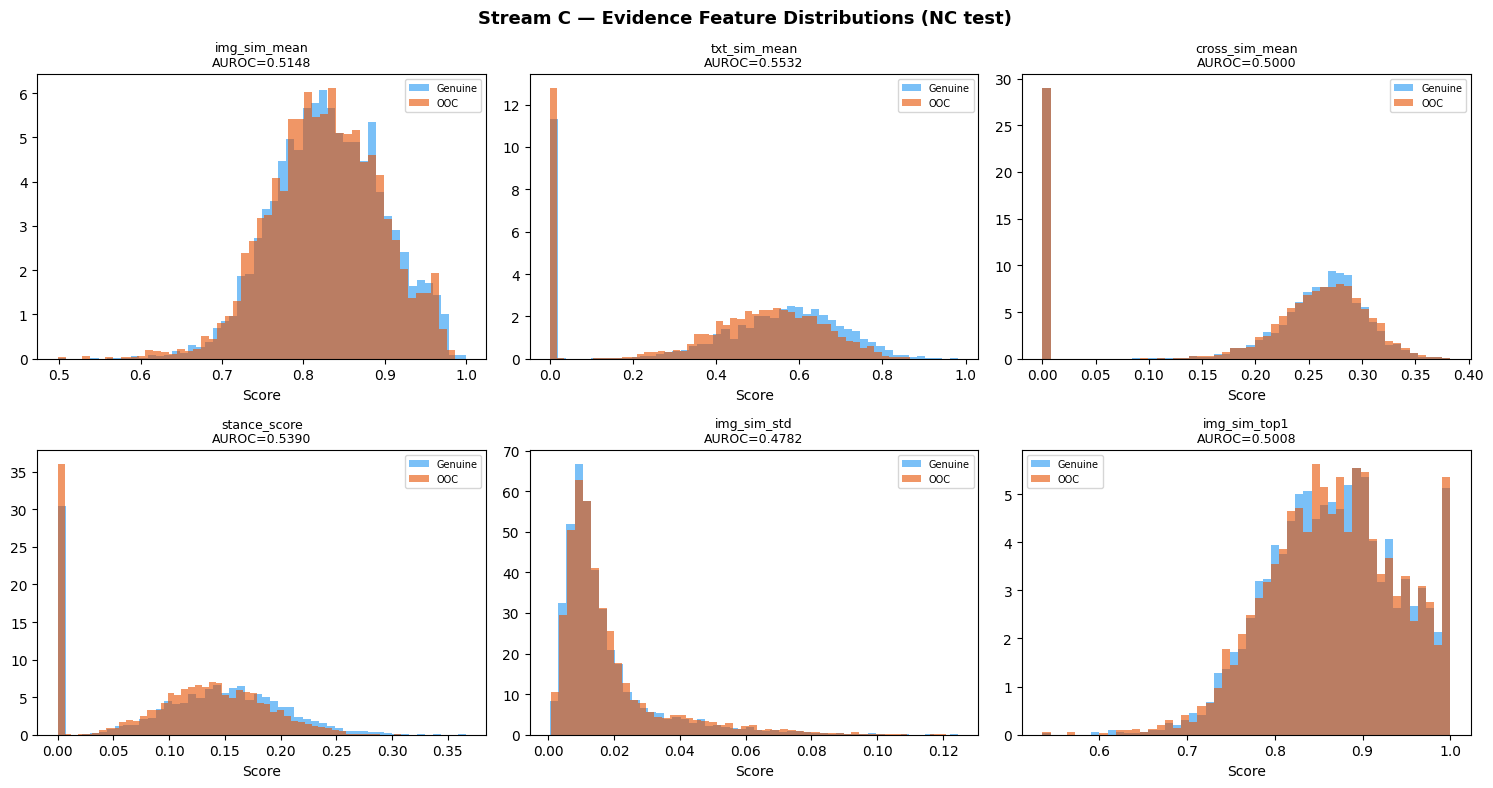

Saved → f:\GitHub\eve-rag\paper\figures\stream_c_evidence_distributions.png


In [ ]:
import matplotlib.pyplot as plt
FIG_DIR = ROOT / 'paper' / 'figures'

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_feats = ['img_sim_mean', 'txt_sim_mean', 'cross_sim_mean',
              'stance_score', 'img_sim_std', 'img_sim_top1']

mat = matrices['test']
labels = mat['labels']

for ax, feat in zip(axes.flat, plot_feats):
    col_idx = FEAT_COLS.index(feat)
    vals    = mat['features'][:, col_idx]
    ax.hist(vals[labels==0], bins=50, alpha=0.6, color='#2196f3',
            label='Genuine', density=True)
    ax.hist(vals[labels==1], bins=50, alpha=0.6, color='#e65100',
            label='OOC',     density=True)
    auc_val = roc_auc_score(labels, -vals) if np.std(vals) > 1e-6 else 0.5
    ax.set_title(f'{feat}\nAUROC={auc_val:.4f}', fontsize=9)
    ax.legend(fontsize=7); ax.set_xlabel('Score')

plt.suptitle('Stream C — Evidence Feature Distributions (NC test)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_c_evidence_distributions.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 11. Summary

In [ ]:
print("=" * 60)
print("STREAM C — evidence_retrieval.ipynb COMPLETE")
print("=" * 60)
print(f"  Retrieval method: FAISS IndexFlatIP (cosine) on NC train")
print(f"  K = {K} neighbours per query")
print(f"  Feature dim: {len(FEAT_COLS)}")
print(f"  Features: {FEAT_COLS}")
print()
print("  Evidence AUROC (stance_score, negated):")
for key in ('val', 'test', 'verite', 'mmfake'):
    mat = matrices[key]
    col = FEAT_COLS.index('stance_score')
    vals = mat['features'][:, col]
    if np.std(vals) > 1e-6:
        auc = roc_auc_score(mat['labels'], -vals)
        print(f"    {key:12s}: {auc:.4f}")
print()
print("  Saved files:")
for f in sorted(EVIDENCE_DIR.iterdir()):
    print(f"    {f.name:40s} {f.stat().st_size/1e6:6.1f} MB")
print()
print("  Next notebook: stance_scoring.ipynb")

STREAM C — evidence_retrieval.ipynb COMPLETE
  Retrieval method: FAISS IndexFlatIP (cosine) on NC train
  K = 10 neighbours per query
  Feature dim: 10
  Features: ['img_sim_max', 'img_sim_mean', 'img_sim_std', 'img_sim_top1', 'txt_sim_max', 'txt_sim_mean', 'txt_sim_top1', 'cross_sim_max', 'cross_sim_mean', 'stance_score']

  Evidence AUROC (stance_score, negated):
    val         : 0.5389
    test        : 0.5390
    verite      : 0.5012
    mmfake      : 0.5108

  Saved files:
    evidence_mmfake.pkl                         0.5 MB
    evidence_test.pkl                           0.4 MB
    evidence_train.pkl                          4.2 MB
    evidence_val.pkl                            0.4 MB
    evidence_verite.pkl                         0.1 MB
    feature_names.pkl                           0.0 MB

  Next notebook: stance_scoring.ipynb


In [ ]:
import os
for f in os.listdir('cache/evidence'):
    print(f)